# Speakers on the travel-time map

The STT4SG-350 speaker municipalities on two maps: geography (LV95) and the 1950 car travel-time map, on which
straight-line distance ≈ travel time.

The travel-time map is built in the `historische-reisezeiten` repository (`playground/06_travel_time_mds_map.ipynb`):
metric MDS of the 1950 travel times between all Swiss municipalities, aligned onto LV95, and a displacement field
smoothed over `sigma` that moves any LV95 point onto the travel-time map. That notebook saves the field
(`MIV_1950_warp.npz`); copy it to `data/geo/travel_time_MIV_1950_warp.npz`.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from shapely.geometry import LineString
from shapely.ops import transform

DATA_DIR = Path("../data/stt4sg-350_v2-1")
GEO_DIR = Path("../data/geo")
WARP_FILE = GEO_DIR / "travel_time_MIV_1950_warp.npz"

table = pd.read_csv(DATA_DIR / "zip_municipality.csv", dtype={"zipcode": str})
cantons = gpd.read_file(GEO_DIR / "cantons.geojson")
switzerland = cantons.union_all()

warp = np.load(WARP_FILE)
anchor_xy, anchor_tt_xy, sigma, scale = warp["anchor_xy"], warp["anchor_tt_xy"], float(warp["sigma"]), float(warp["scale"])
key = str(warp["travel_time_key"])
print(f"{key}: {len(anchor_xy)} zones, sigma {sigma / 1000:.0f} km, 1 km on the map ≙ {1000 / scale:.1f} min")

MIV_1950: 2930 zones, sigma 12 km, 1 km on the map ≙ 1.5 min


In [2]:
def warp_points(P, chunk=4000):
    # LV95 -> travel-time map: p + the Gaussian-weighted mean displacement of the zones around p
    P = np.asarray(P, dtype=float)
    out = np.empty_like(P)
    d = anchor_tt_xy - anchor_xy
    for k in range(0, len(P), chunk):
        q = P[k:k + chunk]
        w = np.exp(-((q[:, None, :] - anchor_xy[None]) ** 2).sum(-1) / (2 * sigma ** 2))
        out[k:k + chunk] = q + (w @ d) / w.sum(1, keepdims=True)
    return out


def warp_geometry(geom):
    return transform(lambda x, y: warp_points(np.column_stack([x, y])).T, geom)

One point per speaker municipality at its centroid (`muni_E`/`muni_N`, what the models use), sized by the number of
speakers and coloured by dialect region (the region with most speakers where there are several), with the colours of
`01_plot_speaker_map.ipynb`.

In [3]:
REGION_COLORS = dict(zip(sorted(table.dialect_region.unique()), plt.get_cmap("tab10").colors))

located = table.dropna(subset=["bfs_nr", "muni_E"])
per_region = located.groupby(["bfs_nr", "dialect_region"], as_index=False).n_speakers.sum()
speakers = (per_region.sort_values("n_speakers").drop_duplicates("bfs_nr", keep="last")
            .drop(columns="n_speakers")
            .merge(located.groupby("bfs_nr", as_index=False).agg(n_speakers=("n_speakers", "sum"),
                                                                  muni_E=("muni_E", "first"),
                                                                  muni_N=("muni_N", "first"))))
geo_xy = speakers[["muni_E", "muni_N"]].to_numpy()
tt_xy = warp_points(geo_xy)
moved = np.linalg.norm(tt_xy - geo_xy, axis=1)
print(f"{int(speakers.n_speakers.sum())} speakers in {len(speakers)} municipalities "
      f"({int(table.n_speakers.sum() - speakers.n_speakers.sum())} without location); "
      f"moved by {np.median(moved) / 1000:.1f} km (median), {moved.max() / 1000:.1f} km (max)")

315 speakers in 161 municipalities (1 without location); moved by 15.8 km (median), 45.1 km (max)


In [4]:
STEP = 10_000
xmin, ymin, xmax, ymax = switzerland.bounds
gx, gy = np.arange(xmin, xmax + STEP, STEP), np.arange(ymin, ymax + STEP, STEP)
fine = lambda a, b: np.linspace(a, b, 200)
grid = gpd.GeoDataFrame(geometry=[LineString(np.column_stack([np.full(200, x), fine(ymin, ymax)])) for x in gx]
                        + [LineString(np.column_stack([fine(xmin, xmax), np.full(200, y)])) for y in gy], crs=2056)
grid = gpd.clip(grid, switzerland.buffer(2_000))
grid_tt = grid.assign(geometry=grid.geometry.apply(warp_geometry))
cantons_tt = cantons.assign(geometry=cantons.geometry.simplify(200).apply(warp_geometry))

/var/folders/d_/r89f0qt56b91xr3wj5bwft480000gr/T/ipykernel_17828/3936611902.py:14: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  return transform(lambda x, y: warp_points(np.column_stack([x, y])).T, geom)
/var/folders/d_/r89f0qt56b91xr3wj5bwft480000gr/T/ipykernel_17828/3936611902.py:14: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  return transform(lambda x, y: warp_points(np.column_stack([x, y])).T, geom)


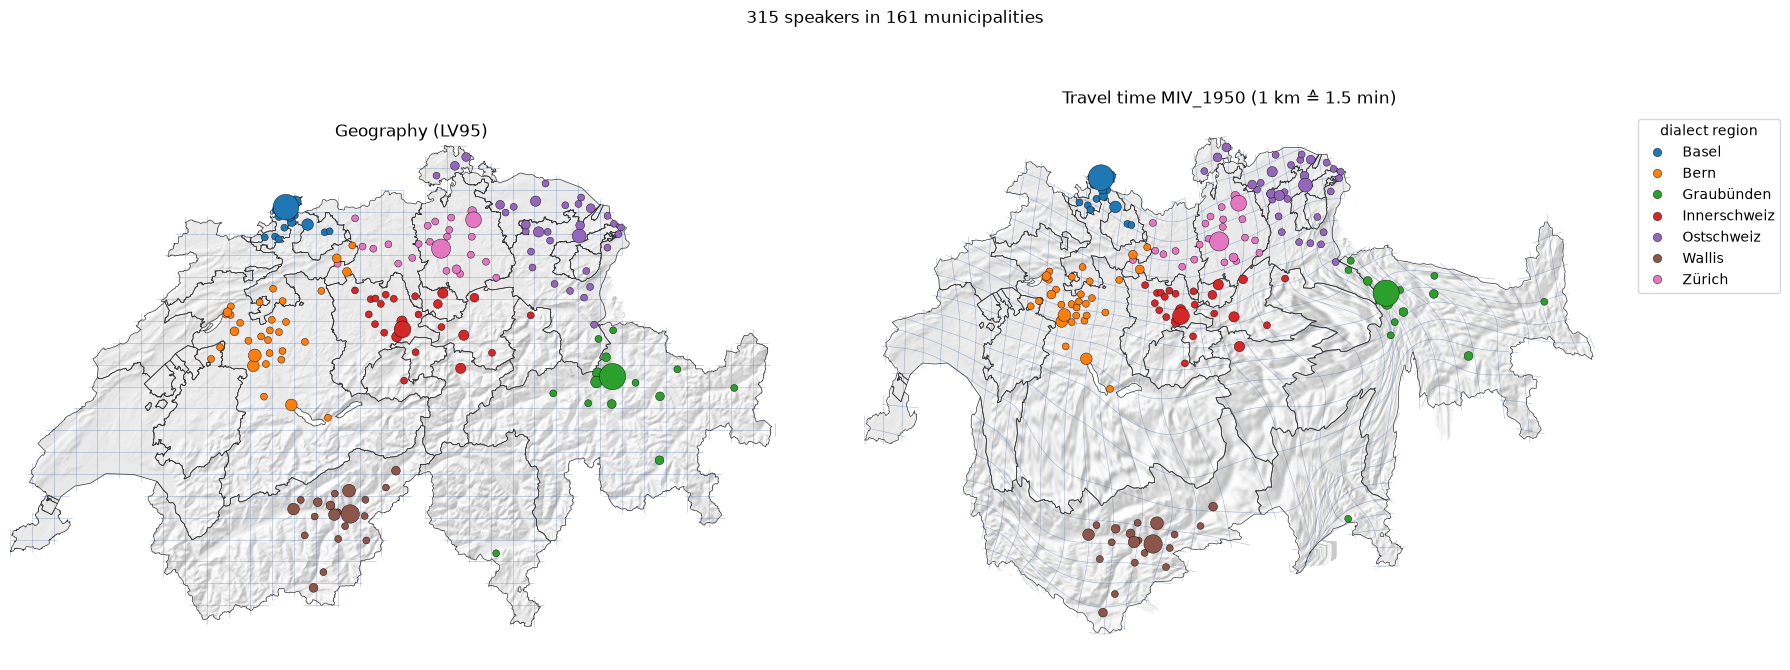

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
size = 10 + 15 * speakers.n_speakers
color = speakers.dialect_region.map(REGION_COLORS)
layers = [
    (warp["hillshade"], warp["hillshade_extent"], grid, cantons, geo_xy, "Geography (LV95)"),
    (warp["hillshade_warped"], warp["hillshade_warped_extent"], grid_tt, cantons_tt, tt_xy,
     f"Travel time {key} (1 km ≙ {1000 / scale:.1f} min)"),
]
for ax, (relief, extent, graticule, outlines, xy, title) in zip(axes, layers):
    ax.imshow(relief, cmap="gray", extent=extent, origin="upper", alpha=0.35)
    graticule.plot(ax=ax, color="#4c72b0", linewidth=0.4, alpha=0.5)
    outlines.boundary.plot(ax=ax, color="#333333", linewidth=0.5)
    ax.scatter(*xy.T, s=size, c=color, edgecolors="black", linewidths=0.3, zorder=3)
    ax.set_title(title)
    ax.set_axis_off()
    ax.set_aspect("equal")
axes[1].legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor=c, markeredgecolor="black",
                               markeredgewidth=0.3, label=r) for r, c in REGION_COLORS.items()],
               title="dialect region", loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle(f"{int(speakers.n_speakers.sum())} speakers in {len(speakers)} municipalities")
plt.tight_layout()
plt.show()